# Cross-Validation vs Bayesian Regularization for Ridge Regression

We look at an example of time series data $y_t$. We fit the model:
\begin{align*}
   y_t = \mu_t + \epsilon_t
\end{align*}
where $\epsilon_t \overset{\text{i.i.d}}{\sim} N(0, \sigma^2)$, and
\begin{align*}
   \mu_t = \beta_0 + \beta_1 (t - 1) + \sum_{j=2}^{n-2} \beta_j (t - j)_+. 
\end{align*}
Estimation of $\beta_0, \dots, \beta_{n-1}$ will be done via ridge regression: 
\begin{align*}
   \text{minimize} \left[\sum_{t=1}^n \left(y_t - \beta_0 - \beta_1(t - 1) - \sum_{j=2}^{n-1} \beta_j (t - j)_+\right)^2 + \lambda \sum_{j=2}^{n-1} \beta_j^2 \right]. 
\end{align*}
for a fixed $\lambda > 0$. The choice of $\lambda$ is done either via 5-fold Cross-Valication (for a particular selection of folds), or via the Bayesian method discussed in Lectures 12-13. The Bayesian method also yields an alternative estimate of $\beta_0, \dots, \beta_{n-1}$ (along with uncertainty quantification). 

We work with the FRED data on weekly initial unemployment claims (from https://fred.stlouisfed.org/series/ICSA). 

In [73]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

  observation_date    ICSA
0       1967-01-07  208000
1       1967-01-14  207000
2       1967-01-21  217000
3       1967-01-28  204000
4       1967-02-04  216000
5       1967-02-11  229000
6       1967-02-18  229000
7       1967-02-25  242000
8       1967-03-04  310000
9       1967-03-11  241000
     observation_date    ICSA
3108       2026-08-01  200000
3109       2026-08-08  212000
3110       2026-08-15  207000
3111       2026-08-22  204000
3112       2026-08-29  207000
3113       2026-09-05  207000
3114       2026-09-12  198000
3115       2026-09-19  198000
3116       2026-09-26  199000
3117       2026-10-03  197000


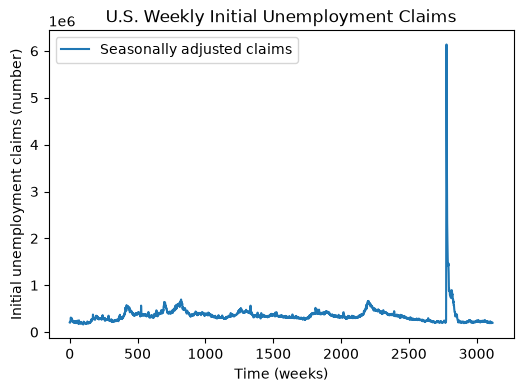

In [74]:
claims = pd.read_csv('ICSA_11Oct2026.csv')
print(claims.head(10))
print(claims.tail(10))

plt.figure(figsize=(6, 4))
plt.plot(claims['ICSA'], label="Seasonally adjusted claims")
plt.xlabel("Time (weeks)")
plt.ylabel("Initial unemployment claims (number)")
plt.title("U.S. Weekly Initial Unemployment Claims")
plt.legend()
plt.show()

We use all available data before March 2020 so that the exceptional surge in unemployment claims during COVID-19 does not dominate the analysis.

2774


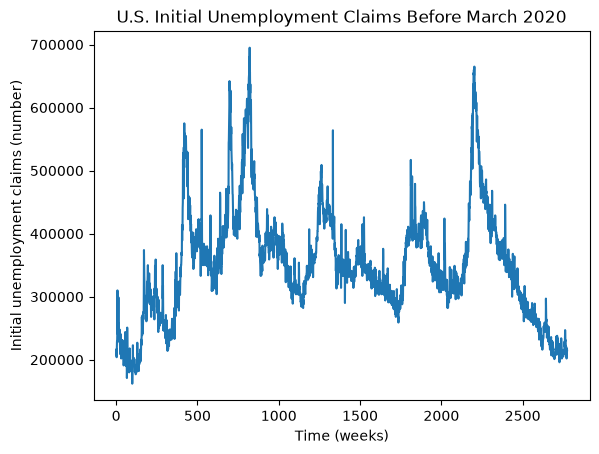

In [75]:
dates = pd.to_datetime(claims.iloc[:, 0])

y = claims.loc[dates < "2020-03-01", "ICSA"].to_numpy()

print(len(y))
plt.plot(y)
plt.xlabel("Time (weeks)")
plt.ylabel("Initial unemployment claims (number)")
plt.title("U.S. Initial Unemployment Claims Before March 2020")
plt.show()

We will apply our model to this data, and obtain estimates of the underlying trend. Note that, in the context of our model, trend means the fitted function:
\begin{align*}
  \hat{\beta}_0 + \hat{\beta}_1 (t - 1) + \sum_{j=2}^{n-1} \hat{\beta}_j (t - j)_+. 
\end{align*}
Recall the following function for fitting ridge regressions. 

In [76]:
def solve_ridge_formula(X, y, lambda_val, penalty_start=2):
    n, p = X.shape
    J = np.diag(np.r_[np.zeros(penalty_start), np.ones(p - penalty_start)])
    return np.linalg.solve(X.T @ X + lambda_val * J, X.T @ y)

Given $\lambda$, the ridge regression estimate is computed as follows. 

In [77]:
n = len(y)
print(n)
x = np.arange(1, n + 1, dtype=float)
knots = np.arange(1, n)                       # c = 1, ..., n-1  (c = 1 gives the x-1 column)
X = np.column_stack([np.ones(n), np.maximum(x[:, None] - knots, 0)])
print(X)

2774
[[1.000e+00 0.000e+00 0.000e+00 ... 0.000e+00 0.000e+00 0.000e+00]
 [1.000e+00 1.000e+00 0.000e+00 ... 0.000e+00 0.000e+00 0.000e+00]
 [1.000e+00 2.000e+00 1.000e+00 ... 0.000e+00 0.000e+00 0.000e+00]
 ...
 [1.000e+00 2.771e+03 2.770e+03 ... 1.000e+00 0.000e+00 0.000e+00]
 [1.000e+00 2.772e+03 2.771e+03 ... 2.000e+00 1.000e+00 0.000e+00]
 [1.000e+00 2.773e+03 2.772e+03 ... 3.000e+00 2.000e+00 1.000e+00]]


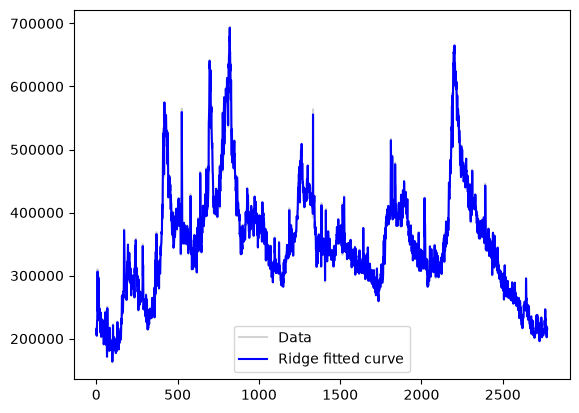

In [80]:
lambda_value = 1e-2
b_ridge = solve_ridge_formula(X, y, lambda_val = lambda_value)
plt.plot(y, color = 'lightgray', label = 'Data')
ridge_fitted = np.dot(X, b_ridge)
plt.plot(ridge_fitted, color = 'blue', label = 'Ridge fitted curve')
plt.legend()
plt.show()

It is clear that when $\lambda = \lambda_{\min} := 10^{-2}$, the fitted trend function nearly reproduces the data, while when $\lambda = \lambda_{\max} := 10^{13}$, the fitted trend function fits a line to the data. Below we see which value of $\lambda$ in the range $[\lambda_{\min}, \lambda_{\max}]$ will be picked by the various methods. 

In [81]:
lambda_min = 1e-2
lambda_max = 1e13
numlambda = 25
lambda_candidates =  np.logspace(np.log10(lambda_min), np.log10(lambda_max), num=numlambda)
print(lambda_candidates)

[1.00000000e-02 4.21696503e-02 1.77827941e-01 7.49894209e-01
 3.16227766e+00 1.33352143e+01 5.62341325e+01 2.37137371e+02
 1.00000000e+03 4.21696503e+03 1.77827941e+04 7.49894209e+04
 3.16227766e+05 1.33352143e+06 5.62341325e+06 2.37137371e+07
 1.00000000e+08 4.21696503e+08 1.77827941e+09 7.49894209e+09
 3.16227766e+10 1.33352143e+11 5.62341325e+11 2.37137371e+12
 1.00000000e+13]


First, we use the Cross-Validation method that we used in lectures. 

In [82]:
def ridge_cv(X, y, lambda_candidates):
    y = np.asarray(y, dtype=float)  # Ensure positional indexing
    n = len(y)
    k = 5
    fold_size = n // k
    folds = []

    for i in range(k):
        start = i * fold_size
        end = (i + 1) * fold_size if i < k - 1 else n  # last fold includes remainder
        test_indices = np.arange(start, end)
        train_indices = np.concatenate([np.arange(0, start), np.arange(end, n)])
        folds.append((train_indices, test_indices))

    cv_errors = {lamb: 0 for lamb in lambda_candidates}

    for train_index, test_index in folds:
        X_train = X[train_index]
        X_test = X[test_index]
        y_train = y[train_index]
        y_test = y[test_index]

        for lamb in lambda_candidates:
            beta = solve_ridge_formula(X_train, y_train, lambda_val=lamb)
            y_pred = np.dot(X_test, beta)
            squared_errors = (y_test - y_pred) ** 2
            cv_errors[lamb] += np.sum(squared_errors)

    for lamb in lambda_candidates:
        cv_errors[lamb] /= n

    best_lambda = min(cv_errors, key=cv_errors.get)
    return best_lambda, cv_errors


In [83]:
best_lambda, cv_errors = ridge_cv(X, y, lambda_candidates)
print(best_lambda)
for lamb, error in sorted(cv_errors.items()):
    print(f"Lambda = {lamb:.2f}, CV Error = {error:.6f}")


31622776601.683792
Lambda = 0.01, CV Error = 6044800264801.299805
Lambda = 0.04, CV Error = 4583338220512.932617
Lambda = 0.18, CV Error = 2972813447403.703125
Lambda = 0.75, CV Error = 1150648448062.330322
Lambda = 3.16, CV Error = 223170347690.249420
Lambda = 13.34, CV Error = 71945038833.736679
Lambda = 56.23, CV Error = 138940419802.570526
Lambda = 237.14, CV Error = 269596496587.779053
Lambda = 1000.00, CV Error = 122089139443.817184
Lambda = 4216.97, CV Error = 58547640767.912560
Lambda = 17782.79, CV Error = 372394665563.129211
Lambda = 74989.42, CV Error = 683332286501.163452
Lambda = 316227.77, CV Error = 672604194167.156494
Lambda = 1333521.43, CV Error = 459667639455.585693
Lambda = 5623413.25, CV Error = 253188813519.846924
Lambda = 23713737.06, CV Error = 110470558664.877991
Lambda = 100000000.00, CV Error = 38630679318.691208
Lambda = 421696503.43, CV Error = 18114264777.164085
Lambda = 1778279410.04, CV Error = 14903490337.725771
Lambda = 7498942093.32, CV Error = 136204

The $\lambda$ value selected by this method is on the higher side. So the fitted trend function will be very smooth. 

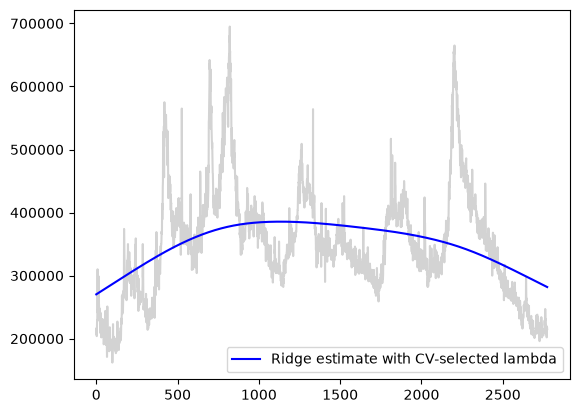

In [84]:
b_ridge = solve_ridge_formula(X, y, lambda_val = best_lambda) 
plt.plot(y, color = 'lightgray')
ridge_fitted_cv_1 = np.dot(X, b_ridge)
plt.plot(ridge_fitted_cv_1, color = 'blue', label = 'Ridge estimate with CV-selected lambda')
plt.legend()
plt.show()

Obviously this is a poor estimate of the underlying trend. This CV method uses consecutive data points as folds. The five folds used by CV can be visualized as follows. 

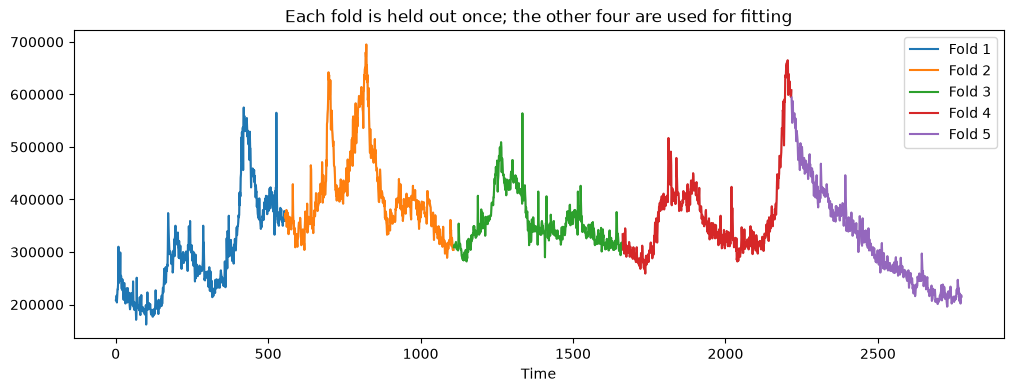

In [88]:
n = len(y)
y_values = np.asarray(y)
t = np.arange(1, n + 1)
fold_size = n // 5
folds = []
colors = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple"]

plt.figure(figsize=(12, 4))
plt.plot(t, y_values, color="lightgray")

for i in range(5):
    start = i * fold_size
    end = (i + 1) * fold_size if i < 4 else n
    indices = np.arange(start, end)
    folds.append(indices)

    plt.plot(
        t[indices], y_values[indices],
        color=colors[i], linewidth=1.5, label=f"Fold {i + 1}"
    )

plt.xlabel("Time")
plt.title("Each fold is held out once; the other four are used for fitting")
plt.legend()
plt.show()

If we fix a fold (for testing), and fit the model on the other 4 folds, the fitted function can be visualized (for a fixed $\lambda$) as follows. 

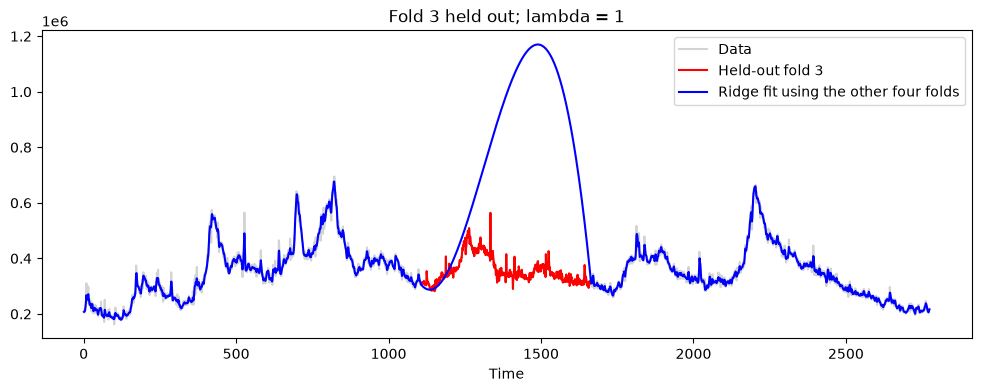

In [92]:
# Choose a fold and a fixed lambda
fold_number = 3       # Choose 1, 2, 3, 4, or 5
lambda_val = 1e0
#lambda_val = 1e9

y_values = np.asarray(y)
test_index = folds[fold_number - 1]
train_index = np.setdiff1d(np.arange(n), test_index)

beta = solve_ridge_formula(
    X[train_index], y_values[train_index], lambda_val=lambda_val
)
fitted = X @ beta     # Evaluate at ALL time points

plt.figure(figsize=(12, 4))
plt.plot(t, y_values, color="lightgray", label="Data")
plt.plot(
    t[test_index], y_values[test_index],
    color="red", linewidth=1.5, label=f"Held-out fold {fold_number}"
)
plt.plot(
    t, fitted, color="blue",
    label="Ridge fit using the other four folds"
)

plt.xlabel("Time")
plt.title(f"Fold {fold_number} held out; lambda = {lambda_val:g}")
plt.legend()
plt.show()

Suppose the test fold is the 3rd fold. It should be clear from the above that if $\lambda$ is chosen small, then the fitted function looks quite off compared to the actual data for fold = 3. This is the reason why a large $\lambda$ is being chosen by CV.

Now we change the CV method by taking the five folds randomly. This was basically the CV method used in the last lab. We can fit this CV also with the same function 'ridge_cv' by permuting the rows of $X$ and $y$ before calling 'ridge_cv'. Indeed, the original function makes consecutive folds in the **row order it receives**. Supplying a random permutation of the paired rows therefore creates random folds in calendar time. We do not alter `ridge_cv` (or `solve_ridge_formula`).

Note that it we should permute **both** `X` and `y` with the same indices. Shuffling only `y`, or constructing a new time basis after shuffling it, would change the regression problem. The original `X`, `y`, and calendar years below remain chronological for final fitting and plotting.


In [93]:
rng = np.random.default_rng(123)
permutation = rng.permutation(len(y))

best_lambda_random, cv_errors_random = ridge_cv(
    X[permutation], y[permutation], lambda_candidates
)

print(f"Random-fold CV choice: {best_lambda_random:g}")
for lamb, error in sorted(cv_errors_random.items()):
    print(f"Lambda = {lamb:.2f}, CV Error = {error:.6f}")


Random-fold CV choice: 3.16228
Lambda = 0.01, CV Error = 272745490.619259
Lambda = 0.04, CV Error = 262306220.845535
Lambda = 0.18, CV Error = 244923818.592328
Lambda = 0.75, CV Error = 229469165.409373
Lambda = 3.16, CV Error = 221911915.121373
Lambda = 13.34, CV Error = 224097584.509332
Lambda = 56.23, CV Error = 234316090.221303
Lambda = 237.14, CV Error = 255078837.166333
Lambda = 1000.00, CV Error = 290830557.667755
Lambda = 4216.97, CV Error = 345683295.627062
Lambda = 17782.79, CV Error = 435432552.065656
Lambda = 74989.42, CV Error = 591952498.679296
Lambda = 316227.77, CV Error = 853250442.777322
Lambda = 1333521.43, CV Error = 1232515535.905905
Lambda = 5623413.25, CV Error = 1777389144.216505
Lambda = 23713737.06, CV Error = 2458629596.932100
Lambda = 100000000.00, CV Error = 3133899885.518766
Lambda = 421696503.43, CV Error = 3637188609.825331
Lambda = 1778279410.04, CV Error = 4145433433.561262
Lambda = 7498942093.32, CV Error = 5037328266.327239
Lambda = 31622776601.68, C

The $\lambda$ now chosen is quite small. This should lead to estimates that are much more noisy (compared to the previous case). 

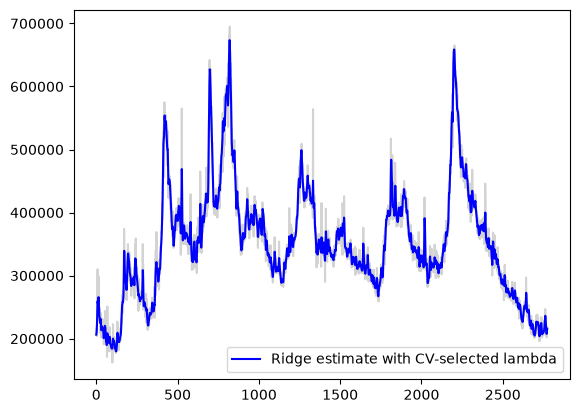

In [94]:
b_ridge_random = solve_ridge_formula(X, y, lambda_val = best_lambda_random) 
plt.plot(y, color = 'lightgray')
ridge_fitted_cv_random = np.dot(X, b_ridge_random)
plt.plot(ridge_fitted_cv_random, color = 'blue', label = 'Ridge estimate with CV-selected lambda')
plt.legend()
plt.show()

Perhaps, the trend estimate now is too smooth. 

So, depending on how the folds are chosen, CV can give $\lambda$ that is quite high or quite low. Below, we plot the folds used in the second CV (random folds). 

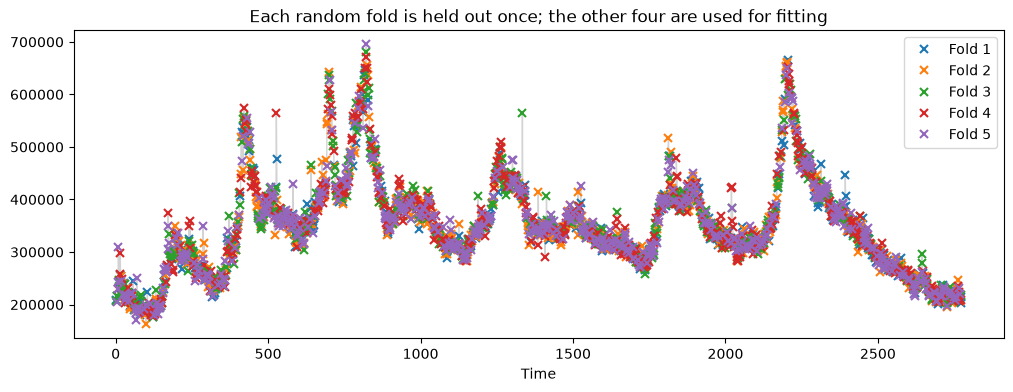

In [97]:
folds = []
y_values = np.asarray(y)
colors = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple"]

plt.figure(figsize=(12, 4))
plt.plot(t, y_values, color="lightgray", linewidth=1)

for i in range(5):
    start = i * fold_size
    end = (i + 1) * fold_size if i < 4 else n
    indices = permutation[start:end]
    folds.append(indices)

    plt.plot(
        t[indices], y_values[indices],
        linestyle="none", marker="x",
        markersize=6, markeredgewidth=1.5,
        color=colors[i], label=f"Fold {i + 1}"
    )

plt.xlabel("Time")
plt.title("Each random fold is held out once; the other four are used for fitting")
plt.legend()
plt.show()

The distinct folds are hard to see now because they are randomly present all over the data. 

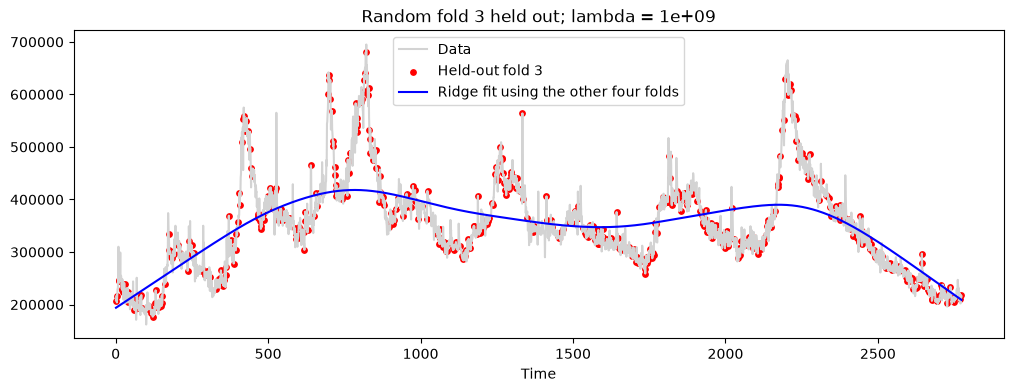

In [99]:
fold_number = 3       # Choose 1, 2, 3, 4, or 5
lambda_val = 1e9      # Change as desired

test_index = folds[fold_number - 1]
train_index = np.setdiff1d(np.arange(n), test_index)

beta = solve_ridge_formula(
    X[train_index], y[train_index], lambda_val=lambda_val
)
fitted = X @ beta     # Evaluate at ALL time points in original order

# Plot 2: fitted function and held-out observations
plt.figure(figsize=(12, 4))
plt.plot(t, y, color="lightgray", label="Data")
plt.scatter(
    t[test_index], y[test_index],
    color="red", s=15, label=f"Held-out fold {fold_number}"
)
plt.plot(t, fitted, color="blue", label="Ridge fit using the other four folds")

plt.xlabel("Time")
plt.title(f"Random fold {fold_number} held out; lambda = {lambda_val:g}")
plt.legend()
plt.show()

Here is some intuition for why the two CV methods are behaving so differently. This is because the two CV schemes assess different prediction tasks. With consecutive folds, we remove a long stretch of observations, so the fitted curve must predict across a large gap or extrapolate beyond the training data. Flexible (overfitting) fits can perform poorly in these regions, leading CV to favor a large $\lambda$ (smooth fit). With random folds, most held-out observations have nearby training observations. A flexible fit can use these neighbors to track the data and predict the held-out values accurately, favoring a small $\lambda$. Thus, the preferred amount of smoothing depends strongly on whether we assess prediction across long gaps or interpolation between nearby observations.

Next let us try Bayesian regularization for this problem. 

In [108]:
n = len(y)
J = np.diag(np.concatenate([[0, 0], np.ones(n - 2)]))
XTX, XTy, yTy = X.T @ X, X.T @ y, y.T @ y

numlambda = 25
lambda_candidates =  np.logspace(np.log10(lambda_min), np.log10(lambda_max), num=numlambda)

loglambda_gr = np.log(lambda_candidates)
logpost_loglambda = np.zeros(len(loglambda_gr))

for i, ell in enumerate(loglambda_gr):
    Mat = XTX + np.exp(ell) * J
    beta_mean = np.linalg.solve(Mat, XTy)
    sgn, logdet = np.linalg.slogdet(Mat)

    logpost_loglambda[i] = (
        (n/2-1) * ell
        - 0.5 * logdet
        - (n/2 - 1) * np.log(yTy - XTy.T @ beta_mean)
    )

post_loglambda = np.exp(logpost_loglambda - np.max(logpost_loglambda))

# Probability weights: these sum to 1.
prob_loglambda = post_loglambda / np.sum(post_loglambda)

# Density values: their integral is approximately 1.
step = loglambda_gr[1] - loglambda_gr[0]
post_loglambda = prob_loglambda / step

The $\lambda$-values along with the log posterior and posterior probabilities are printed below. 

In [112]:
for lam, logpost, prob in zip(
    lambda_candidates, logpost_loglambda, prob_loglambda
):
    print(
        f"Lambda = {lam:.6e}, "
        f"Log posterior = {logpost:.6f}, "
        f"Posterior probability = {prob:.6f}"
    )

Lambda = 1.000000e-02, Log posterior = -39349.146181, Posterior probability = 0.000000
Lambda = 4.216965e-02, Log posterior = -39213.268461, Posterior probability = 0.000000
Lambda = 1.778279e-01, Log posterior = -38944.516186, Posterior probability = 0.000000
Lambda = 7.498942e-01, Log posterior = -38633.681110, Posterior probability = 0.000000
Lambda = 3.162278e+00, Log posterior = -38380.291737, Posterior probability = 0.000000
Lambda = 1.333521e+01, Log posterior = -38220.433532, Posterior probability = 0.000000
Lambda = 5.623413e+01, Log posterior = -38163.001885, Posterior probability = 1.000000
Lambda = 2.371374e+02, Log posterior = -38210.543166, Posterior probability = 0.000000
Lambda = 1.000000e+03, Log posterior = -38355.714596, Posterior probability = 0.000000
Lambda = 4.216965e+03, Log posterior = -38595.649078, Posterior probability = 0.000000
Lambda = 1.778279e+04, Log posterior = -38942.510041, Posterior probability = 0.000000
Lambda = 7.498942e+04, Log posterior = -393

Here we are only using 25 $\lambda$ values (as in CV). The posterior probability is 1 exactly for one $\lambda$ (and zero for all other $\lambda$'s). This $\lambda$ value is the posterior maximizer. This value is small but not as small as the $\lambda$ selected by the random-fold CV. So the fitted function will still be noisy (tracking the original data)but not as noisy as the ridge estimate obtained by the random-fold CV method. 

In [113]:
idx = np.argmax(logpost_loglambda)
lambda_bayes = lambda_candidates[idx]

print(f"Bayesian lambda:        {lambda_bayes:.6e}")
print(f"Ridge CV lambda:        {best_lambda:.6e}")
print(f"Ridge random-fold CV:   {best_lambda_random:.6e}")

Bayesian lambda:        5.623413e+01
Ridge CV lambda:        3.162278e+10
Ridge random-fold CV:   3.162278e+00


Below are the estimates of the trend functions corresponding to each of these $\lambda$ choices. 

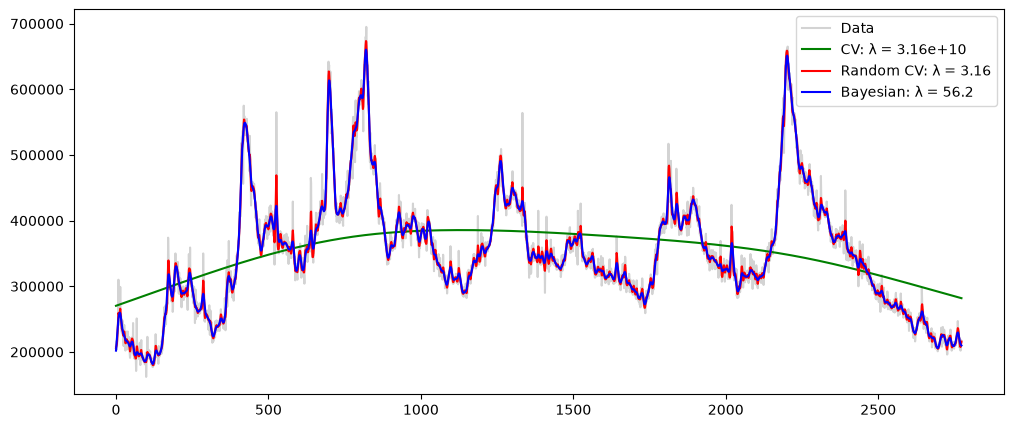

In [116]:
fit_cv = X @ solve_ridge_formula(X, y, lambda_val=best_lambda)
fit_random = X @ solve_ridge_formula(X, y, lambda_val=best_lambda_random)
fit_bayes = X @ solve_ridge_formula(X, y, lambda_val=lambda_bayes)

plt.figure(figsize=(12, 5))
plt.plot(y, color="lightgray", label="Data")
plt.plot(fit_cv, color="green", label=f"CV: λ = {best_lambda:.3g}")
plt.plot(fit_random, color="red", label=f"Random CV: λ = {best_lambda_random:.3g}")
plt.plot(fit_bayes, color="blue", label=f"Bayesian: λ = {lambda_bayes:.3g}")
plt.legend()
plt.show()

It is hard to spot the differences between the random CV estimate and the Bayesian estimate. One can zoom in to see that the Bayesian estimate is indeed smoother. 

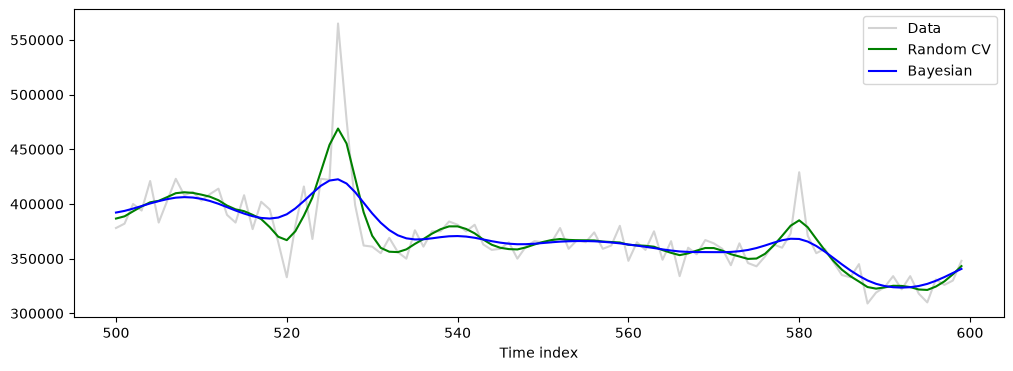

In [122]:
start, end = 500, 600
t_zoom = np.arange(start, end)

plt.figure(figsize=(12, 4))
plt.plot(t_zoom, np.asarray(y)[start:end], color="lightgray", label="Data")
plt.plot(t_zoom, fit_random[start:end], color="green", label="Random CV")
plt.plot(t_zoom, fit_bayes[start:end], color="blue", label="Bayesian")
plt.xlabel("Time index")
plt.legend()
plt.show()

One can also run the full Bayesian method to get posterior samples of $\beta_0, \dots, \beta_{n-1}$, which also tracks uncertainty in $\lambda$. The relevant formulae here are given here. We work with the following prior: 
\begin{align*}
   \beta_0, \beta_1 \overset{\text{i.i.d}}{\sim} N(0, C) ~~ \text{ and } ~~ \beta_2, \dots, \beta_{n-1} \overset{\text{i.i.d}}{\sim} N(0, \sigma^2/\lambda). 
\end{align*}
We also treat $\sigma$ and $\lambda$ as unknown parameters and assign the prior: 
\begin{align*}
   \lambda \sim f_{\lambda}(\lambda) ~~ \text{ and } ~~ \log \sigma \sim \text{unif}(-C, C)
\end{align*}
where
\begin{align*}
   f_{\lambda}(\lambda) \propto \frac{I(\lambda_{\min} \leq \lambda \leq \lambda_{\max})}{\lambda} ~\text{ which corresponds to}~ \log \lambda \sim \text{unif}(\log \lambda_{\min}, \log \lambda_{\max}). 
\end{align*}
As derived in the lecture, the posterior of $\beta, \sigma, \lambda$ then becomes: 
\begin{align*}
   \beta \mid \text{data}, \sigma, \lambda \sim N\left((X^TX + \lambda J)^{-1} X^T y, \sigma^2 (X^T X + \lambda J)^{-1} \right)
\end{align*}
and
\begin{align*}
   \frac{1}{\sigma^2} \mid \text{data}, \lambda \sim \text{Gamma} \left(\frac{n}{2} - 1, \frac{y^T y - y^T X(X^T X + \lambda J)^{-1} X^T y}{2} \right). 
\end{align*}
and
\begin{align*}
  f_{\lambda\mid\text{data}}(\lambda) \propto f_{\lambda}(\lambda) \frac{\lambda^{(n-2)/2}|X^TX+\lambda J|^{-1/2}}
  {\left(y^Ty-y^TX(X^TX+\lambda J)^{-1}X^Ty\right)^{(n/2)-1}}
\end{align*}
The key here is the posterior for $\lambda$. We compute this posterior numerically below by taking a grid of values for $\log \lambda$. The computation proceeds more stably if we evaluate the posterior density of $\log \lambda$: 
\begin{align*}
   f_{\log \lambda \mid \text{data}}(x) \propto \frac{e^{(n/2 - 1)x} |X^T X + e^x J|^{-1/2}}{\left( y^T y - y^T X (X^TX + e^x J)^{-1} X^T y \right)^{n/2 - 1}} I\{\log \lambda_{\min} \leq x \leq \log \lambda_{\max}\}. 
\end{align*}
The code for doing all this computation is given below. Explanation for how the code relates to the above formulae is explained after the code. 

We need to select a large number of $\lambda$ values, and evaluate the posterior at these values. Depending on the number of $\lambda$ values chosen, and the number of posterior samples we want to obtain, this can be computationally slower. 

In [125]:
from scipy.linalg import cho_solve, solve_triangular

n = len(y)
shape = n / 2 - 1
J = np.diag(np.r_[0, 0, np.ones(n - 2)])
XTX, XTy, yTy = X.T @ X, X.T @ y, y.T @ y

lambda_candidates = np.geomspace(lambda_min, lambda_max, 1000)
loglambda_gr = np.log(lambda_candidates)

beta_means = np.zeros((n, len(lambda_candidates)))
rates = np.zeros(len(lambda_candidates))
logpost_loglambda = np.zeros(len(lambda_candidates))

# Compute and save quantities needed again during sampling
for i, lam in enumerate(lambda_candidates):
    L = np.linalg.cholesky(XTX + lam * J)
    beta_means[:, i] = cho_solve((L, True), XTy)
    rates[i] = (yTy - XTy @ beta_means[:, i]) / 2

    logpost_loglambda[i] = (
        shape * loglambda_gr[i]
        - np.log(np.diag(L)).sum()
        - shape * np.log(2 * rates[i])
    )

weights = np.exp(logpost_loglambda - logpost_loglambda.max())
prob_loglambda = weights / weights.sum()
post_loglambda = prob_loglambda / (loglambda_gr[1] - loglambda_gr[0])

# Sample grid indices so we can reuse the saved quantities
N = 1000
indices = np.random.choice(len(lambda_candidates), N, p=prob_loglambda)
lambda_samples = lambda_candidates[indices]
sig_samples = np.sqrt(1 / np.random.gamma(shape, 1 / rates[indices]))
betahats = np.zeros((n, N))

# Handle all draws with the same lambda together
for j in np.unique(indices):
    selected = np.flatnonzero(indices == j)
    L = np.linalg.cholesky(XTX + lambda_candidates[j] * J)
    noise = solve_triangular(
        L.T, np.random.randn(n, len(selected)), lower=False
    )
    betahats[:, selected] = (
        beta_means[:, j, None] + sig_samples[selected] * noise
    )

muhats = X @ betahats
beta_est = betahats.mean(axis=1)
mu_est = muhats.mean(axis=1)

Here is an explanation of the above code, and how it relates to the posterior formulae. 

Write
$$
A_\lambda=X^TX+\lambda J,\qquad
b=X^Ty,\qquad c=y^Ty,\qquad a=\frac{n}{2}-1.
$$

The quantities $X^TX$, $b$, and $c$ do not depend on $\lambda$, so the code computes them only once. For each value of $\lambda$, we need
$$
m_\lambda=A_\lambda^{-1}b,\qquad
q_\lambda=c-b^Tm_\lambda,\qquad
\log|A_\lambda|.
$$

Here $m_\lambda$ is the conditional posterior mean of $\beta$, and $q_\lambda/2$ is the rate parameter in the conditional Gamma distribution of $1/\sigma^2$.

**Cholesky decomposition**

Although these formulas involve a matrix inverse, the code does not construct that inverse. Instead, it uses a Cholesky decomposition:
$$
A_\lambda=L_\lambda L_\lambda^T.
$$

The matrix $L_\lambda$ is lower triangular, meaning that all entries above its diagonal are zero. Its diagonal entries are positive:
$$
L_\lambda=
\begin{pmatrix}
\ell_{11} & 0 & \cdots & 0\\
\ell_{21} & \ell_{22} & \cdots & 0\\
\vdots & \vdots & \ddots & \vdots\\
\ell_{n1} & \ell_{n2} & \cdots & \ell_{nn}
\end{pmatrix}.
$$

Such a factorization exists for every real symmetric positive definite matrix. In our problem, $A_\lambda$ has this property because $X$ has full column rank and, for every nonzero vector $v$,
$$
v^TA_\lambda v=\|Xv\|^2+\lambda v^TJv>0.
$$

The command `L = np.linalg.cholesky(XTX + lam * J)` computes this lower triangular factor.

The advantage of the factorization is that equations involving triangular matrices are easy to solve. For example, to solve $L_\lambda u=b$, we first obtain $u_1$ from the first equation:
$$
u_1=\frac{b_1}{\ell_{11}}.
$$

The second equation then gives
$$
u_2=\frac{b_2-\ell_{21}u_1}{\ell_{22}}.
$$

We continue down the rows, finding one new unknown at each step. This is called **forward substitution**. Equations involving $L_\lambda^T$, which is upper triangular, can similarly be solved starting from the last row and working upward. This is called **back substitution**.

**Computing the posterior mean**

To compute $m_\lambda=A_\lambda^{-1}b$, we solve $A_\lambda m_\lambda=b$. Using the factorization, this becomes
$$
L_\lambda L_\lambda^T m_\lambda=b.
$$

We solve this through two triangular systems:
$$
L_\lambda u=b,\qquad L_\lambda^T m_\lambda=u.
$$

The command `cho_solve((L, True), XTy)` performs these two steps. The argument `True` specifies that the supplied factor is lower triangular. This computes the desired posterior mean without explicitly forming $A_\lambda^{-1}$.

**Computing the determinant**

The same Cholesky factor also gives the determinant. The determinant of a triangular matrix is the product of its diagonal entries, so
$$
|A_\lambda|
=|L_\lambda|\,|L_\lambda^T|
=\left(\prod_{j=1}^n\ell_{jj}\right)^2.
$$

Consequently,
$$
\log|A_\lambda|=2\sum_{j=1}^n\log\ell_{jj}.
$$

The code therefore obtains $-\frac12\log|A_\lambda|$ as `-np.log(np.diag(L)).sum()`. Working with a sum of logarithms avoids forming a product that might be extremely large or small.

Once $m_\lambda$ is available, the remaining quantity is
$$
q_\lambda=c-b^Tm_\lambda.
$$

The code stores $m_\lambda$ in a column of `beta_means` and stores $q_\lambda/2$ in `rates`. These quantities will be needed again during posterior sampling, so saving them avoids repeating their calculation.

**Computing the posterior grid weights**

Let $x_g=\log\lambda_g$, for $g=1,\ldots,G$, be equally spaced grid points between $\log\lambda_{\min}$ and $\log\lambda_{\max}$.

The logarithm of the posterior density of $\log\lambda$, up to an additive constant that does not depend on $g$, is
$$
\begin{aligned}
h_g
&=a x_g-\frac12\log|A_{\lambda_g}|-a\log q_{\lambda_g}\\
&=a x_g-\sum_{j=1}^n\log(L_{\lambda_g})_{jj}
-a\log q_{\lambda_g}.
\end{aligned}
$$

These values are stored in `logpost_loglambda`.

To turn them into posterior grid weights, the code computes
$$
w_g=
\frac{\exp(h_g-h_{\max})}
{\sum_{k=1}^G\exp(h_k-h_{\max})},
\qquad
h_{\max}=\max_{1\leq k\leq G}h_k.
$$

Subtracting $h_{\max}$ does not change the normalized weights: it multiplies every unnormalized weight by the same constant. It improves numerical stability by making the largest exponential equal to one.

Because the grid is equally spaced in $\log\lambda$, its common spacing cancels when the weights are normalized. The resulting weights sum to one and approximate posterior masses associated with the grid points. They are stored in `prob_loglambda`.

If the grid spacing is $\Delta x$, then $w_g/\Delta x$ approximates the posterior density of $\log\lambda$ at $x_g$. These density values are stored in `post_loglambda`.

**Sampling from the posterior**

Posterior sampling follows the factorization
$$
p(\beta,\sigma,\lambda\mid y)
=
p(\lambda\mid y)\,
p(\sigma\mid\lambda,y)\,
p(\beta\mid\sigma,\lambda,y).
$$

First, the code samples grid indices using probabilities $w_1,\ldots,w_G$. A sampled index $g$ corresponds to $\lambda=\lambda_g$ and gives immediate access to its saved mean $m_{\lambda_g}$ and rate $r_g=q_{\lambda_g}/2$.

Next, conditional on this sampled $\lambda_g$, we draw
$$
T=\frac{1}{\sigma^2}
\sim\operatorname{Gamma}(\text{shape}=a,\text{rate}=r_g),
\qquad
\sigma=T^{-1/2}.
$$

NumPy specifies a Gamma distribution using its shape and **scale**, rather than its shape and rate. Since scale is the reciprocal of rate, the appropriate call is `np.random.gamma(shape, 1/rate)`. The code draws all the required values of $\sigma$ at once.

Finally, we must sample
$$
\beta\mid\sigma,\lambda,y
\sim N(m_\lambda,\sigma^2A_\lambda^{-1}).
$$

To do this, generate a vector $z$ of independent standard normal variables and solve
$$
L_\lambda^T u=z.
$$

Then set
$$
\beta=m_\lambda+\sigma u.
$$

To verify this construction, observe that
$$
u=L_\lambda^{-T}z
$$
and hence
$$
\operatorname{Cov}(u)
=L_\lambda^{-T}L_\lambda^{-1}
=(L_\lambda L_\lambda^T)^{-1}
=A_\lambda^{-1}.
$$

Therefore, the constructed vector has mean $m_\lambda$ and covariance $\sigma^2A_\lambda^{-1}$, as required.

The code computes $u$ using `solve_triangular(L.T, z, lower=False)`. The transpose matters: we solve with $L_\lambda^T$, which is upper triangular.

**Avoiding repeated calculations**

Several posterior draws may select the same grid value of $\lambda$. The sampling loop therefore visits each distinct sampled grid index only once. For that index, it recomputes one Cholesky factor and uses it for all the corresponding draws.

The independent standard normal vectors are arranged as columns of a matrix, allowing the triangular solver to process them together. Each column uses its own sampled $\sigma$.

Thus, the code saves the coefficient means and Gamma rates from the grid calculation, while recomputing Cholesky factors only for the distinct grid values selected during sampling. This avoids storing a large collection of matrix factors and avoids a separate factorization for every posterior draw.

A Cholesky factorization requires order $n^3$ operations, whereas solving a triangular system for one vector requires order $n^2$ operations. Reusing the factors can therefore substantially reduce computation.

**Constructing the posterior curves**

For each sampled coefficient vector $\beta^{(s)}$, the corresponding mean curve is
$$
\mu^{(s)}=X\beta^{(s)}.
$$

The command `muhats = X @ betahats` computes all these curves together. Their average,
$$
\widehat{\mu}
=\frac{1}{N}\sum_{s=1}^N\mu^{(s)},
$$
approximates the posterior mean $E[\mu\mid y]$.

The plot shows the observations in light gray, the sampled mean curves in light coral, and their average in black. The computation has a grid approximation from discretizing $\lambda$ and Monte Carlo error from using finitely many posterior draws.

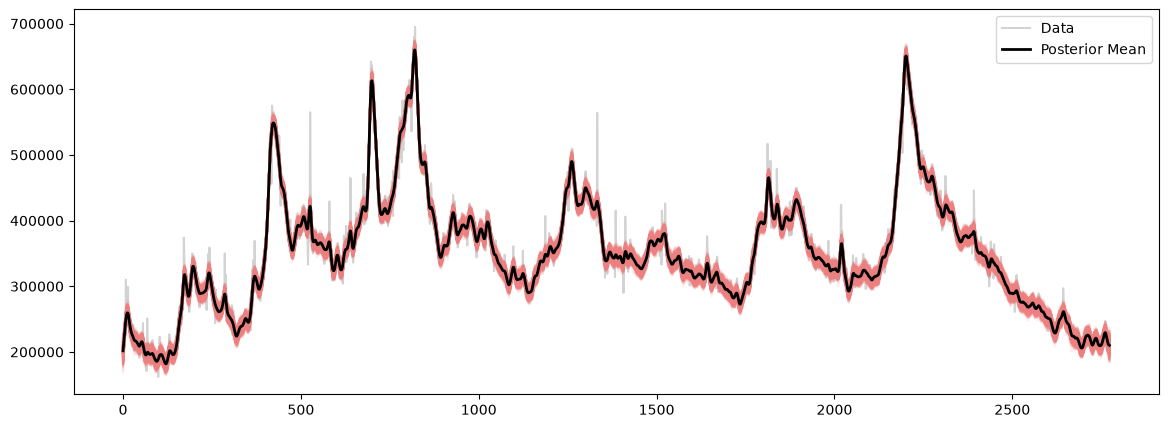

In [126]:
plt.figure(figsize=(14, 5))
plt.plot(np.asarray(y), color="lightgray", label="Data")
plt.plot(muhats, color="lightcoral", alpha=0.15)
plt.plot(mu_est, color="black", linewidth=2, label="Posterior Mean")
plt.legend()
plt.show()

To visualize these posterior samples better, we can zoom into certain shorter time intervals. 

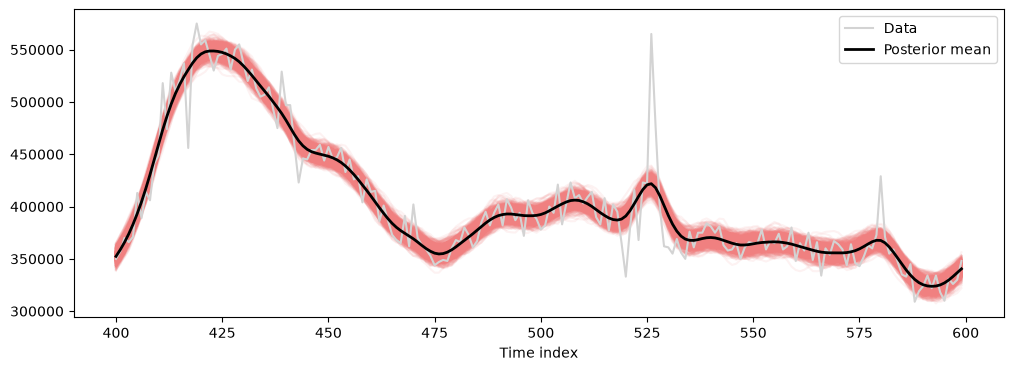

In [129]:
start, end = 400, 600
t_zoom = np.arange(start, end)

plt.figure(figsize=(12, 4))
plt.plot(t_zoom, muhats[start:end, :], color="lightcoral", alpha=0.1)
plt.plot(t_zoom, np.asarray(y)[start:end], color="lightgray", label="Data")
plt.plot(t_zoom, mu_est[start:end], color="black", linewidth=2, label="Posterior mean")
plt.xlabel("Time index")
plt.legend()
plt.show()

This notebook compares cross-validation and Bayesian regularization for estimating the trend in weekly U.S. initial unemployment claims before March 2020. Consecutive-fold CV selects a large $\lambda$ and produces a very smooth fit, while random-fold CV selects a much smaller $\lambda$ and follows more short-term variation. Bayesian tuning gives an intermediate amount of smoothing in this example. These differences illustrate how the choice of validation folds and modeling assumptions influences the estimated trend. Full Bayesian inference additionally accounts for uncertainty in $\lambda$, $\sigma$, and $\beta$, producing posterior samples of the trend. Cholesky decomposition and reuse of intermediate calculations make this computation more efficient.